# A/B Test: Does a more visible "Contact agent" button get more buyers to contact an agent?

**Scenario.** On a home-listing page, the new design (**treatment**) moves the *Contact agent* button
higher on the page. Half of 120,000 visitors saw the old page (**control**), half saw the new one.

**Question.** Did more people contact an agent with the new design, without making the page worse?

**Plan**
1. Check the 50/50 split worked
2. Compare contact rates (SQL)
3. Test whether the difference is real (statistics)
4. Break it down by device
5. Check a guardrail: page load time
6. Make a recommendation

*Data is simulated (companies don't publish real A/B test data), see `generate_data.py`.*

In [1]:
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

df = pd.read_csv("data/experiment_users.csv")

# Load into a SQL database so we can query it with SQL
con = sqlite3.connect(":memory:")
df.to_sql("users", con, index=False)

def sql(query):
    return pd.read_sql(query, con)

print(df.shape)
print(df.head().to_string(index=False))

(120000, 6)
 user_id   variant  device  sessions  contacted_agent  page_load_ms
       1   control desktop         4                0          1759
       2 treatment  mobile         4                0          1039
       3 treatment  mobile         2                0          1597
       4 treatment  mobile         2                0          1060
       5   control  mobile         3                0          1224


## Step 1: Check the split (sample ratio mismatch)

Users were assigned 50/50. If the groups are very uneven, something broke (a bug, a logging problem)
and the results can't be trusted. A chi-square test checks whether the split is close enough to 50/50.

In [2]:
split = sql("""
    SELECT variant, COUNT(*) AS users
    FROM users
    GROUP BY variant
""")
print(split.to_string(index=False))

chi2, p_srm = stats.chisquare(split["users"])
print(f"\nSplit check p-value = {p_srm:.3f}  ->  {'OK' if p_srm > 0.001 else 'PROBLEM: investigate before going further'}")

  variant  users
  control  59996
treatment  60004

Split check p-value = 0.982  ->  OK


## Step 2: Contact rate in each group (SQL)

In [3]:
results = sql("""
    SELECT variant,
           COUNT(*)                      AS users,
           SUM(contacted_agent)          AS contacted,
           ROUND(AVG(contacted_agent), 4) AS contact_rate
    FROM users
    GROUP BY variant
""")
print(results.to_string(index=False))

  variant  users  contacted  contact_rate
  control  59996       6200        0.1033
treatment  60004       6654        0.1109


## Step 3: Is the difference real, or just luck?

**Two-proportion z-test.** If the new design had *no* effect, how likely is a difference this big?
That probability is the **p-value**. Below 0.05, we call the result statistically significant.

We also compute a **95% confidence interval**: the range the true lift probably falls in.

In [4]:
def fmt_p(p):
    return "< 0.0001" if p < 0.0001 else f"{p:.4f}"


def ab_test(users_a, conv_a, users_b, conv_b):
    """Compare conversion rates of A (control) and B (treatment)."""
    rate_a, rate_b = conv_a / users_a, conv_b / users_b
    diff = rate_b - rate_a
    se = np.sqrt(rate_a * (1 - rate_a) / users_a + rate_b * (1 - rate_b) / users_b)
    z = diff / se
    p_value = 2 * (1 - stats.norm.cdf(abs(z)))
    ci_low, ci_high = diff - 1.96 * se, diff + 1.96 * se
    return {
        "control_rate": rate_a, "treatment_rate": rate_b,
        "relative_lift": diff / rate_a,
        "ci_low": ci_low / rate_a, "ci_high": ci_high / rate_a,   # as relative lift
        "p_value": p_value,
    }

c = results.set_index("variant")
overall = ab_test(c.loc["control", "users"], c.loc["control", "contacted"],
                  c.loc["treatment", "users"], c.loc["treatment", "contacted"])

print(f"Control rate:    {overall['control_rate']:.2%}")
print(f"Treatment rate:  {overall['treatment_rate']:.2%}")
print(f"Relative lift:   {overall['relative_lift']:+.1%}  (95% CI {overall['ci_low']:+.1%} to {overall['ci_high']:+.1%})")
print(f"p-value:         {fmt_p(overall['p_value'])}")

Control rate:    10.33%
Treatment rate:  11.09%
Relative lift:   +7.3%  (95% CI +3.9% to +10.7%)
p-value:         < 0.0001


## Step 4: Does it work the same on every device?

Same test, separately for mobile, desktop and tablet. Testing 3 groups gives 3 chances of a lucky
result, so we use a stricter cutoff: **0.05 / 3 ≈ 0.017** (Bonferroni correction).

In [5]:
by_device = sql("""
    SELECT device, variant,
           COUNT(*)             AS users,
           SUM(contacted_agent) AS contacted
    FROM users
    GROUP BY device, variant
""")

rows = []
for device, g in by_device.groupby("device"):
    g = g.set_index("variant")
    r = ab_test(g.loc["control", "users"], g.loc["control", "contacted"],
                g.loc["treatment", "users"], g.loc["treatment", "contacted"])
    rows.append({"device": device, "users": g["users"].sum(), **r})
seg = pd.DataFrame(rows).sort_values("users", ascending=False)
seg["significant"] = seg["p_value"] < 0.05 / len(seg)

show = seg[["device", "users", "relative_lift", "ci_low", "ci_high", "p_value", "significant"]].copy()
for col in ["relative_lift", "ci_low", "ci_high"]:
    show[col] = show[col].map("{:+.1%}".format)
show["p_value"] = show["p_value"].map(fmt_p)
print(show.to_string(index=False))

 device  users relative_lift ci_low ci_high  p_value  significant
 mobile  72158        +10.0%  +5.6%  +14.4% < 0.0001         True
desktop  41901         +2.0%  -3.7%   +7.7%   0.4838        False
 tablet   5941        +12.0%  -3.8%  +27.8%   0.1372        False


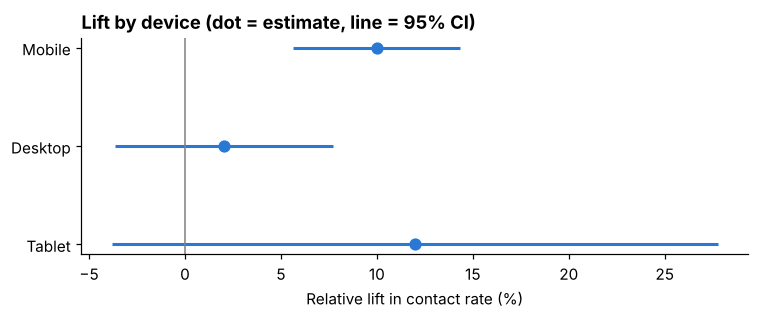

In [6]:
# Chart: lift by device with 95% confidence intervals
fig, ax = plt.subplots(figsize=(7, 3))
y = range(len(seg))
ax.errorbar(seg["relative_lift"] * 100, y,
            xerr=[(seg["relative_lift"] - seg["ci_low"]) * 100, (seg["ci_high"] - seg["relative_lift"]) * 100],
            fmt="o", color="#2a78d6", ecolor="#2a78d6", capsize=0, lw=2, ms=7)
ax.axvline(0, color="gray", lw=1)
ax.set_yticks(list(y), seg["device"].str.capitalize())
ax.invert_yaxis()
ax.set_xlabel("Relative lift in contact rate (%)")
ax.set_title("Lift by device (dot = estimate, line = 95% CI)", loc="left", fontweight="bold")
for s in ["top", "right"]:
    ax.spines[s].set_visible(False)
plt.tight_layout()
plt.show()

## Step 5: Guardrail: did the new page load slower?

A guardrail is a metric that must **not** get meaningfully worse. Our rule, set before the test:
page load may not increase by more than **100 ms**. We use a t-test (page load is a number, not yes/no).

In [7]:
load = sql("""
    SELECT variant, ROUND(AVG(page_load_ms), 1) AS avg_page_load_ms
    FROM users
    GROUP BY variant
""")
print(load.to_string(index=False))

a = df.loc[df.variant == "control", "page_load_ms"]
b = df.loc[df.variant == "treatment", "page_load_ms"]
diff_ms = b.mean() - a.mean()
se_ms = np.sqrt(a.var() / len(a) + b.var() / len(b))
print(f"\nDifference: {diff_ms:+.0f} ms (95% CI {diff_ms - 1.96*se_ms:+.0f} to {diff_ms + 1.96*se_ms:+.0f} ms)")
print("Guardrail:", "PASS" if diff_ms + 1.96 * se_ms < 100 else "FAIL")

  variant  avg_page_load_ms
  control            1299.3
treatment            1330.9

Difference: +32 ms (95% CI +29 to +34 ms)
Guardrail: PASS


## Step 6: Recommendation

In [8]:
mobile = seg.set_index("device").loc["mobile"]
desktop = seg.set_index("device").loc["desktop"]
print(f"""
RESULT
- Overall contact rate: {overall['control_rate']:.2%} -> {overall['treatment_rate']:.2%} ({overall['relative_lift']:+.1%}, p {fmt_p(overall['p_value']) if overall['p_value'] < 0.0001 else '= ' + fmt_p(overall['p_value'])})
- Mobile:  {mobile['relative_lift']:+.1%} (95% CI {mobile['ci_low']:+.1%} to {mobile['ci_high']:+.1%})
- Desktop: {desktop['relative_lift']:+.1%} (95% CI {desktop['ci_low']:+.1%} to {desktop['ci_high']:+.1%})
- Page load: {diff_ms:+.0f} ms, within the 100 ms limit

RECOMMENDATION
{'Launch the new design.' if overall['p_value'] < 0.05 else 'Do not launch yet: the result is not significant.'}
{'The lift is clear on mobile. On desktop it is small and not significant, so the next experiment should focus on the desktop layout.' if mobile['significant'] and not desktop['significant'] else ''}

LIMITATIONS
- Simulated data; real logs would need cleaning (bots, duplicate users).
- We measured contacts, not whether those contacts became home sales.
- Short-term test: a new design can get a temporary boost just from being new.
""")


RESULT
- Overall contact rate: 10.33% -> 11.09% (+7.3%, p < 0.0001)
- Mobile:  +10.0% (95% CI +5.6% to +14.4%)
- Desktop: +2.0% (95% CI -3.7% to +7.7%)
- Page load: +32 ms, within the 100 ms limit

RECOMMENDATION
Launch the new design.
The lift is clear on mobile. On desktop it is small and not significant, so the next experiment should focus on the desktop layout.

LIMITATIONS
- Simulated data; real logs would need cleaning (bots, duplicate users).
- We measured contacts, not whether those contacts became home sales.
- Short-term test: a new design can get a temporary boost just from being new.

